# Lab 1 — Intro to Behavioral TV Data
# Name: Ihor Lemeshko | Group: KM-42

## Setup

In [15]:
import kagglehub
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
DATA = kagglehub.dataset_download("shkarupylomaxim/adtech-lab1-tv-panel/versions/2")

# Colab and Kaggle

programs = pd.read_parquet(f"{DATA}/programs.parquet")
viewings = pd.read_parquet(f"{DATA}/viewings.parquet")
daily_weights = pd.read_parquet(f"{DATA}/daily_weights.parquet")
viewer_attributes = pd.read_parquet(f"{DATA}/viewer_attributes.parquet")
attributes = pd.read_parquet(f"{DATA}/attributes.parquet")

## Task 1.1 — Panel and universe

In [ ]:
# Calculate monthly average weight per person (R and L)

in_tab_persons = daily_weights[daily_weights["resp_type"].isin(["R", "L"])]
monthly_weights = in_tab_persons.groupby("respondent_id")["weight"].mean().reset_index()

n_telecasts = programs["telecast_id"].nunique()
n_programs = programs["program_name"].nunique()
n_networks = programs["network_code"].nunique()

in_tab_hh = daily_weights[daily_weights["resp_type"] == "H"]

n_hh_panel = in_tab_hh["respondent_id"].nunique()
n_persons_panel = in_tab_persons["respondent_id"].nunique()

daily_hh_summary = in_tab_hh.groupby("broadcast_date").agg(
    count=("respondent_id", "nunique"),
    projected=("weight", "sum")
)

daily_persons_summary = in_tab_persons.groupby("broadcast_date").agg(
    count=("respondent_id", "nunique"),
    projected=("weight", "sum")
)

avg_hh_intab = daily_hh_summary["count"].mean()
avg_persons_intab = daily_persons_summary["count"].mean()

avg_us_hh_m = daily_hh_summary["projected"].mean() / 1e6
avg_us_persons_m = daily_persons_summary["projected"].mean() / 1e6

print(f"Telecasts: {n_telecasts}")
print(f"Programs: {n_programs}")
print(f"Networks: {n_networks}")
print(f"Households in panel: {n_hh_panel}")
print(f"Persons in panel: {n_persons_panel}")
print(f"Households in-tab, average day: {avg_hh_intab:.1f}")
print(f"Persons in-tab, average day: {avg_persons_intab:.1f}")
print(f"US TV households represented, average day (M): {avg_us_hh_m:.2f}")
print(f"US persons represented, average day (M): {avg_us_persons_m:.2f}")

Telecasts: 5841
Programs: 246
Networks: 10
Households in panel: 4254
Persons in panel: 10210
Households in-tab, average day: 3878.5
Persons in-tab, average day: 9268.7
US TV households represented, average day (M): 125.80
US persons represented, average day (M): 317.28


## Task 1.2 — Average audience by hour of day

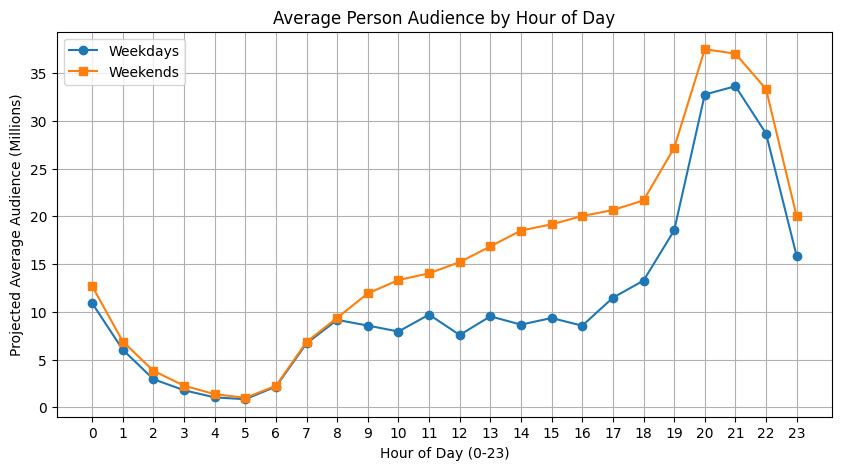

Peak hour, weekdays: 21:00
Peak hour, weekends: 20:00


In [ ]:
# Filter data: retain only individual panel members (R) 
# and long-term visitors (L), excluding guests (S) and households (H)

viewings_persons = viewings[viewings["resp_type"].isin(["R", "L"])].copy()

# Convert timestamp columns from string format to datetime objects

viewings_persons["start_ts"] = pd.to_datetime(viewings_persons["start_ts"])
viewings_persons["end_ts"] = pd.to_datetime(viewings_persons["end_ts"])

# Compute duration for each viewing session in minutes

viewings_persons["duration_min"] = (viewings_persons["end_ts"] - viewings_persons["start_ts"]).dt.total_seconds() / 60.0

# Calculate weighted mean session length:
# each session"s duration is weighted by the respondent"s weight

weighted_mean = np.average(viewings_persons["duration_min"], weights=viewings_persons["weight"])

# Calculate weighted median session length:
# Sort durations and corresponding weights in ascending order

sorted_idx = np.argsort(viewings_persons["duration_min"])
sorted_dur = viewings_persons["duration_min"].iloc[sorted_idx]
sorted_weights = viewings_persons["weight"].iloc[sorted_idx]

# Compute cumulative sum of weights

cumsum_weights = np.cumsum(sorted_weights)
cutoff = cumsum_weights.iloc[-1] / 2.0  # 50% midpoint of total weighted volume

# Find the duration value where cumulative weight reaches the 50% mark

weighted_median = sorted_dur.iloc[np.searchsorted(cumsum_weights, cutoff)]

# Plot the weighted distribution histogram of session lengths

plt.figure(figsize=(8, 4))

# Weights are scaled by 1e6 (Millions) for readable Y-axis labels

plt.hist(viewings_persons["duration_min"], bins=50, weights=viewings_persons["weight"] / 1e6, edgecolor="black")
plt.xlabel("Session Duration (minutes)")
plt.ylabel("Projected Session Minutes (M)")
plt.title("Weighted Distribution of Person Session Length")
plt.grid(True)
plt.show()

# Output formatted results rounded to one decimal place
print(f"Session length, weighted mean (min): {weighted_mean:.1f}")
print(f"Session length, weighted median (min): {weighted_median:.1f}")

**Answer:** On weekends, TV viewing is substantially higher throughout the daytime hours (09:00–17:00) compared to weekdays, as people are generally not at work or school. On weekdays, daytime viewing remains low and flat, with a sharp rise beginning only during Prime Access (around 17:00–18:00) and peaking at 21:00. On weekends, viewing builds up continuously throughout the day and peaks slightly earlier, at 20:00, reaching a higher overall peak audience (~37.5 million viewers vs. ~33.7 million on weekdays).

## Task 1.3 — Session length

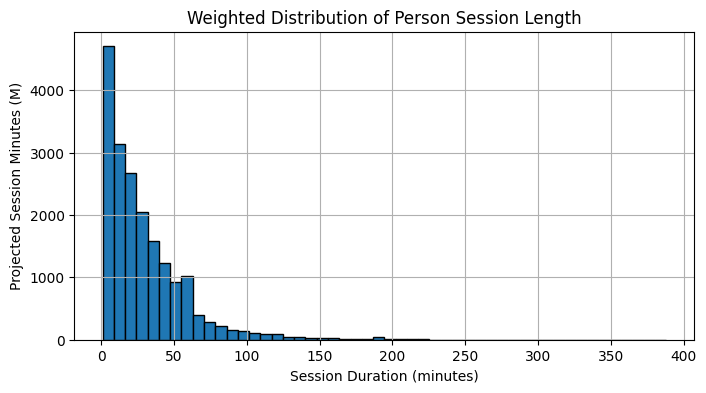

Session length, weighted mean (min): 29.4
Session length, weighted median (min): 21.0


In [25]:
# Filter viewings to include individual panel members (R) and long-term visitors (L) only
viewings_persons = viewings[viewings["resp_type"].isin(["R", "L"])].copy()

# Convert start and end timestamps to datetime objects
viewings_persons["start_ts"] = pd.to_datetime(viewings_persons["start_ts"])
viewings_persons["end_ts"] = pd.to_datetime(viewings_persons["end_ts"])

# Calculate viewing session duration in minutes
viewings_persons["duration_min"] = (viewings_persons["end_ts"] - viewings_persons["start_ts"]).dt.total_seconds() / 60.0

# Compute weighted mean session duration
weighted_mean = np.average(viewings_persons["duration_min"], weights=viewings_persons["weight"])

# Sort session durations and their corresponding weights to calculate weighted median
sorted_idx = np.argsort(viewings_persons["duration_min"])
sorted_dur = viewings_persons["duration_min"].iloc[sorted_idx]
sorted_weights = viewings_persons["weight"].iloc[sorted_idx]

# Calculate cumulative sum of weights and find 50th percentile threshold
cumsum_weights = np.cumsum(sorted_weights)
cutoff = cumsum_weights.iloc[-1] / 2.0
weighted_median = sorted_dur.iloc[np.searchsorted(cumsum_weights, cutoff)]

# Plot weighted histogram of viewing session lengths
plt.figure(figsize=(8, 4))
plt.hist(viewings_persons["duration_min"], bins=50, weights=viewings_persons["weight"] / 1e6, edgecolor="black")
plt.xlabel("Session Duration (minutes)")
plt.ylabel("Projected Session Minutes (M)")
plt.title("Weighted Distribution of Person Session Length")
plt.grid(True)
plt.show()

# Print formatted weighted mean and weighted median values
print(f"Session length, weighted mean (min): {weighted_mean:.1f}")
print(f"Session length, weighted median (min): {weighted_median:.1f}")

**Answer:** The weighted mean (29.4 min) is noticeably higher than the weighted median (21.0 min) because session duration is heavily right-skewed by short channel-surfing sessions mixed with occasional very long sessions. I would present the **weighted median** to a client as the primary metric because it accurately reflects the typical viewer's experience without being distorted by long-session outliers.

## Task 2 — Program reach curve

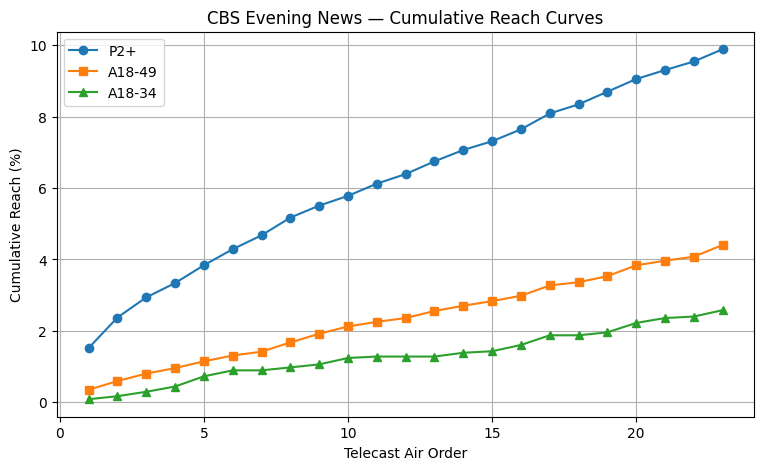

Telecasts of the program: 23
Average household rating (%): 3.2
Average P2+ rating (%): 1.6
Average projected audience (M): 4.93
Final reach P2+ (%): 9.9
Final reach A18-34 (%): 2.6
Final reach A18-49 (%): 4.4


In [ ]:
# Filter CBS Evening News telecasts in chronological air order

cbs_news = programs[(programs["program_name"] == "CBS Evening News") & (programs["network_code"] == "CBS")].sort_values("start_ts").copy()

# Calculate per-telecast ratings and projected audiences

telecast_ratings = []
for _, telecast in cbs_news.iterrows():
    t_start = telecast["start_ts"]
    t_end = telecast["end_ts"]
    b_date = telecast["broadcast_date"]
    
    # Identify households and persons who watched at least 1 minute

    v_hh = viewings[(viewings["network_code"] == "CBS") & (viewings["resp_type"] == "H") & 
                    (viewings["start_ts"] < t_end) & (viewings["end_ts"] > t_start)]
    v_p2 = viewings[(viewings["network_code"] == "CBS") & (viewings["resp_type"].isin(["R", "L"])) & 
                    (viewings["start_ts"] < t_end) & (viewings["end_ts"] > t_start)]
    
    # In-tab universes for the broadcast day

    hh_intab = daily_weights[(daily_weights["broadcast_date"] == b_date) & (daily_weights["resp_type"] == "H")]
    p2_intab = daily_weights[(daily_weights["broadcast_date"] == b_date) & (daily_weights["resp_type"].isin(["R", "L"]))]
    
    hh_weight_sum = hh_intab["weight"].sum()
    p2_weight_sum = p2_intab["weight"].sum()
    
    hh_viewers_weight = hh_intab[hh_intab["respondent_id"].isin(v_hh["respondent_id"])]["weight"].sum()
    p2_viewers_weight = p2_intab[p2_intab["respondent_id"].isin(v_p2["respondent_id"])]["weight"].sum()
    
    hh_rating = (hh_viewers_weight / hh_weight_sum) * 100.0 if hh_weight_sum > 0 else 0
    p2_rating = (p2_viewers_weight / p2_weight_sum) * 100.0 if p2_weight_sum > 0 else 0
    proj_aud_m = p2_viewers_weight / 1e6
    
    telecast_ratings.append({
        "telecast_id": telecast["telecast_id"],
        "hh_rating": hh_rating,
        "p2_rating": p2_rating,
        "proj_aud_m": proj_aud_m
    })

ratings_df = pd.DataFrame(telecast_ratings)

# Calculate monthly average weights and extract exact age (attr_id 300)

in_tab_persons = daily_weights[daily_weights["resp_type"].isin(["R", "L"])]
monthly_weights = in_tab_persons.groupby("respondent_id")["weight"].mean().reset_index()

age_df = viewer_attributes[viewer_attributes["attr_id"] == 300][["respondent_id", "value"]].rename(columns={"value": "age"})
demo_p2 = monthly_weights.merge(age_df, on="respondent_id", how="left")

# Total universe weights using monthly average weights

p2_total_weight = demo_p2["weight"].sum()
a18_34_total_weight = demo_p2[(demo_p2["age"] >= 18) & (demo_p2["age"] <= 34)]["weight"].sum()
a18_49_total_weight = demo_p2[(demo_p2["age"] >= 18) & (demo_p2["age"] <= 49)]["weight"].sum()

# Compute cumulative reach curves

cum_reach_p2, cum_reach_a18_34, cum_reach_a18_49 = [], [], []
seen_p2 = set()

for _, telecast in cbs_news.iterrows():
    t_start = telecast["start_ts"]
    t_end = telecast["end_ts"]
    
    v_p2 = viewings[(viewings["network_code"] == "CBS") & (viewings["resp_type"].isin(["R", "L"])) & 
        (viewings["start_ts"] < t_end) & (viewings["end_ts"] > t_start)]
    
    seen_p2.update(v_p2["respondent_id"].unique())
    current_viewers = demo_p2[demo_p2["respondent_id"].isin(seen_p2)]
    
    reach_p2 = (current_viewers["weight"].sum() / p2_total_weight) * 100.0
    reach_a18_34 = (current_viewers[(current_viewers["age"] >= 18) & (current_viewers["age"] <= 34)]["weight"].sum() / a18_34_total_weight) * 100.0
    reach_a18_49 = (current_viewers[(current_viewers["age"] >= 18) & (current_viewers["age"] <= 49)]["weight"].sum() / a18_49_total_weight) * 100.0
    
    cum_reach_p2.append(reach_p2)
    cum_reach_a18_34.append(reach_a18_34)
    cum_reach_a18_49.append(reach_a18_49)

# Plot Cumulative Reach Curves

plt.figure(figsize=(9, 5))
plt.plot(range(1, len(cbs_news) + 1), cum_reach_p2, label="P2+", marker="o")
plt.plot(range(1, len(cbs_news) + 1), cum_reach_a18_49, label="A18-49", marker="s")
plt.plot(range(1, len(cbs_news) + 1), cum_reach_a18_34, label="A18-34", marker="^")
plt.xlabel("Telecast Air Order")
plt.ylabel("Cumulative Reach (%)")
plt.title("CBS Evening News — Cumulative Reach Curves")
plt.legend()
plt.grid(True)
plt.show()

# Print formatted summary metrics

print(f"Telecasts of the program: {len(cbs_news)}")
print(f"Average household rating (%): {ratings_df["hh_rating"].mean():.1f}")
print(f"Average P2+ rating (%): {ratings_df["p2_rating"].mean():.1f}")
print(f"Average projected audience (M): {ratings_df["proj_aud_m"].mean():.2f}")
print(f"Final reach P2+ (%): {cum_reach_p2[-1]:.1f}")
print(f"Final reach A18-34 (%): {cum_reach_a18_34[-1]:.1f}")
print(f"Final reach A18-49 (%): {cum_reach_a18_49[-1]:.1f}")

**Answer:** Cumulative reach grows continuously over time while single telecast ratings stay roughly flat because different casual viewers tune in on different days. The program reaches the older P2+ audience best (~9.9%), followed by A18–49 (~4.4%) and A18–34 (~2.6%), which directly reflects linear broadcast evening news skewing towards older viewers.

## Task 3 — Program frequency

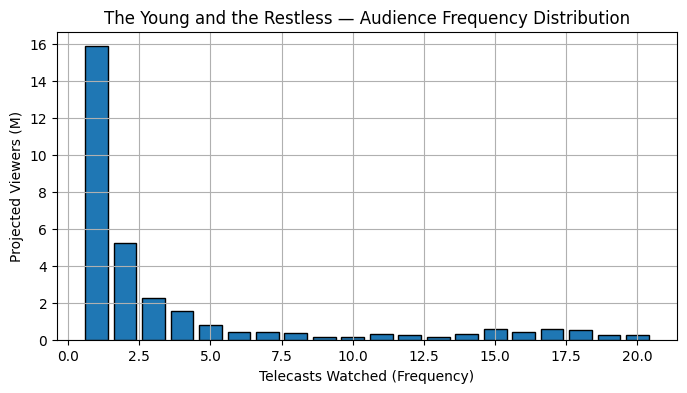

Projected viewers (M): 30.80
Average frequency (weighted): 3.6
Median frequency (weighted): 1.0
Share of views from the most loyal viewers: 0.704


In [27]:
# Filter all October telecasts of "The Young and the Restless" on CBS

soap_telecasts = programs[(programs["program_name"] == "The Young and the Restless") & (programs["network_code"] == "CBS")]
soap_viewings = viewings[(viewings["network_code"] == "CBS") & (viewings["resp_type"].isin(["R", "L"]))]

# Identify unique viewers for each individual telecast

viewer_counts = []
for _, telecast in soap_telecasts.iterrows():
    t_start = telecast["start_ts"]
    t_end = telecast["end_ts"]
    v = soap_viewings[(soap_viewings["start_ts"] < t_end) & (soap_viewings["end_ts"] > t_start)]
    viewer_counts.append(pd.DataFrame({"respondent_id": v["respondent_id"].unique(), "telecast_id": telecast["telecast_id"]}))

all_soap_views = pd.concat(viewer_counts).drop_duplicates()

# Compute per-person viewing frequency (number of telecasts watched)

freq_df = all_soap_views.groupby("respondent_id").size().reset_index(name="frequency")
freq_df = freq_df.merge(monthly_weights, on="respondent_id", how="inner")

# Total projected viewers in millions

total_proj_viewers_m = freq_df["weight"].sum() / 1e6

# Weighted average frequency

weighted_avg_freq = np.average(freq_df["frequency"], weights=freq_df["weight"])

# Weighted median frequency

sorted_f_idx = np.argsort(freq_df["frequency"])
sorted_freq = freq_df["frequency"].iloc[sorted_f_idx]
sorted_f_weights = freq_df["weight"].iloc[sorted_f_idx]
cumsum_f_weights = np.cumsum(sorted_f_weights)
cutoff_f = cumsum_f_weights.iloc[-1] / 2.0
weighted_median_freq = sorted_freq.iloc[np.searchsorted(cumsum_f_weights, cutoff_f)]

# Most loyal viewers: 80th percentile of frequency (whole frequency levels)

p80_cutoff = cumsum_f_weights.iloc[-1] * 0.8
p80_freq_threshold = sorted_freq.iloc[np.searchsorted(cumsum_f_weights, p80_cutoff)]

loyal_viewers = freq_df[freq_df["frequency"] >= p80_freq_threshold]
loyal_views = (loyal_viewers["frequency"] * loyal_viewers["weight"]).sum()
total_views = (freq_df["frequency"] * freq_df["weight"]).sum()
loyal_share = loyal_views / total_views if total_views > 0 else 0

# Plot frequency distribution bar chart

plt.figure(figsize=(8, 4))
freq_dist = freq_df.groupby("frequency")["weight"].sum() / 1e6
plt.bar(freq_dist.index, freq_dist.values, edgecolor="black")
plt.xlabel("Telecasts Watched (Frequency)")
plt.ylabel("Projected Viewers (M)")
plt.title("The Young and the Restless — Audience Frequency Distribution")
plt.grid(True)
plt.show()

# Print metrics following specified formatting guidelines

print(f"Projected viewers (M): {total_proj_viewers_m:.2f}")
print(f"Average frequency (weighted): {weighted_avg_freq:.1f}")
print(f"Median frequency (weighted): {weighted_median_freq:.1f}")
print(f"Share of views from the most loyal viewers: {loyal_share:.3f}")

**Answer:** Average frequency (3.6) is not a fair summary because "the average can lie." The audience distribution is heavily bimodal: over 15 million projected viewers watch only 1 episode (median = 1.0), while a core fan base watches 15–20 telecasts, generating 70.4% of total viewing minutes. The average of 3.6 falls in a sparse middle area that represents almost no actual viewers.

## Task 4 — Networks by age and gender

In [28]:
# Filter viewings to include individual panel members (R) and long-term visitors (L)

v_persons = viewings[viewings['resp_type'].isin(['R', 'L'])].copy()
v_persons['duration_min'] = (pd.to_datetime(v_persons['end_ts']) - pd.to_datetime(v_persons['start_ts'])).dt.total_seconds() / 60.0

# Extract Age (attr_id = 300) and Gender (attr_id 201 = M, 202 = W) directly from viewer_attributes

age_df = viewer_attributes[viewer_attributes['attr_id'] == 300][['respondent_id', 'value']].rename(columns={'value': 'age'})
sex_df = viewer_attributes[viewer_attributes['attr_id'].isin([201, 202])][['respondent_id', 'attr_id']]
sex_df['gender'] = sex_df['attr_id'].map({201: 'M', 202: 'W'})

# Merge viewing records with demographic attributes

v_demo = v_persons.merge(age_df, on='respondent_id', how='left').merge(sex_df, on='respondent_id', how='left')
v_demo['weighted_minutes'] = v_demo['duration_min'] * v_demo['weight']

# Target demographic group filters

target_filters = {
    'M18-34': (v_demo['gender'] == 'M') & (v_demo['age'] >= 18) & (v_demo['age'] <= 34),
    'W18-34': (v_demo['gender'] == 'W') & (v_demo['age'] >= 18) & (v_demo['age'] <= 34),
    'M35-54': (v_demo['gender'] == 'M') & (v_demo['age'] >= 35) & (v_demo['age'] <= 54),
    'W35-54': (v_demo['gender'] == 'W') & (v_demo['age'] >= 35) & (v_demo['age'] <= 54),
    'M55+': (v_demo['gender'] == 'M') & (v_demo['age'] >= 55),
    'W55+': (v_demo['gender'] == 'W') & (v_demo['age'] >= 55)
}

print("=== Top 5 Networks by Target Audience (Projected Minutes M) ===")
for aud_label, cond in target_filters.items():
    top_nets = v_demo[cond].groupby('network_code')['weighted_minutes'].sum() / 1e6
    top_nets = top_nets.sort_values(ascending=False).head(5)
    print(f"\nTarget Audience: {aud_label}")
    print(top_nets.to_string())

# Compute A18-34 demographic share per network (Weighted vs Raw)

net_stats = []
for net in v_demo['network_code'].unique():
    net_data = v_demo[v_demo['network_code'] == net]
    net_a18_34 = net_data[(net_data['age'] >= 18) & (net_data['age'] <= 34)]
    
    tot_weighted = net_data['weighted_minutes'].sum()
    a18_34_weighted = net_a18_34['weighted_minutes'].sum()
    share_weighted = a18_34_weighted / tot_weighted if tot_weighted > 0 else 0
    
    tot_raw = net_data['duration_min'].sum()
    a18_34_raw = net_a18_34['duration_min'].sum()
    share_raw = a18_34_raw / tot_raw if tot_raw > 0 else 0
    
    net_stats.append({
        'network_code': net,
        'share_weighted': share_weighted,
        'share_raw': share_raw
    })

net_df = pd.DataFrame(net_stats)
youngest_net = net_df.sort_values('share_weighted', ascending=False).iloc[0]['network_code']
oldest_net = net_df.sort_values('share_weighted', ascending=True).iloc[0]['network_code']

print(f"\nYoungest network: {youngest_net}")
print(f"Oldest network: {oldest_net}")

=== Top 5 Networks by Target Audience (Projected Minutes M) ===

Target Audience: M18-34
network_code
FOX    4386.649532
NBC    3910.387623
CBS    3044.349725
ABC    3010.781207
FX     1473.962615

Target Audience: W18-34
network_code
FOX    4574.440984
NBC    4527.592683
ABC    3504.858129
CBS    2811.222042
FX     1383.466392

Target Audience: M35-54
network_code
FOX    12804.667952
NBC    10986.683233
ABC     9037.001942
CBS     8134.068701
FX      2370.803334

Target Audience: W35-54
network_code
NBC     11639.102573
FOX     11161.386148
ABC      9438.555757
CBS      8162.798276
HGTV     3051.809345

Target Audience: M55+
network_code
CBS    38274.030580
NBC    34267.411479
FOX    30878.505485
ABC    30793.342523
FNC    27903.709268

Target Audience: W55+
network_code
CBS    47120.320973
NBC    41391.868082
ABC    38840.012626
FOX    36914.718240
FNC    31450.731770

Youngest network: FX
Oldest network: FNC


**Answer:** Weighted share differs from raw panel share because physical panel samples are never perfectly representative of the total population (e.g., younger demographics are under-represented). Weighting corrects sampling bias to project accurately to national totals.

**Bonus answer:** When pitching an older-skewing network to advertisers targeting young adults, highlight:
1. **Absolute Reach Scale:** Broadcast networks still deliver millions of young viewers in absolute volume.
2. **Co-Viewing & Live Events:** High engagement during major live sports and marquee events.